# Linear Regression Starter

Reusable utilities for loading data, training a linear regression model, evaluating it, and plotting predictions.

In [10]:
from pathlib import Path
from typing import Tuple, Union

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

In [11]:
def load_csv(path: Union[str, Path], target: str) -> Tuple[pd.DataFrame, pd.Series]:
    """Load a CSV and separate its feature columns from the target column."""
    data = pd.read_csv(path)
    if target not in data.columns:
        raise ValueError(f"Target column {target!r} was not found in {path}")
    return data.drop(columns=[target]), data[target]


def split_data(
    features: pd.DataFrame,
    target: pd.Series,
    test_size: float = 0.2,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    """Create reproducible train/test partitions."""
    return train_test_split(
        features,
        target,
        test_size=test_size,
        random_state=RANDOM_STATE,
    )


def train_model(features: pd.DataFrame, target: pd.Series) -> LinearRegression:
    """Fit and return a linear regression model."""
    model = LinearRegression()
    model.fit(features, target)
    return model


def evaluate_model(model: LinearRegression, features: pd.DataFrame, target: pd.Series) -> dict:
    """Return common regression metrics for a fitted model."""
    predictions = model.predict(features)
    return {
        "mae": mean_absolute_error(target, predictions),
        "rmse": np.sqrt(mean_squared_error(target, predictions)),
        "r2": r2_score(target, predictions),
    }


def plot_predictions(model: LinearRegression, features: pd.DataFrame, target: pd.Series) -> None:
    """Plot observed versus predicted target values."""
    predictions = model.predict(features)
    plt.figure(figsize=(6, 4))
    plt.scatter(target, predictions, alpha=0.75)
    bounds = [target.min(), target.max()]
    plt.plot(bounds, bounds, "r--", label="perfect prediction")
    plt.xlabel("Observed")
    plt.ylabel("Predicted")
    plt.title("Observed vs. predicted")
    plt.legend()
    plt.tight_layout()
    plt.show()

coefficient: 2.991
intercept: 7.256
{'mae': 1.392, 'rmse': np.float64(1.805), 'r2': 1.0}


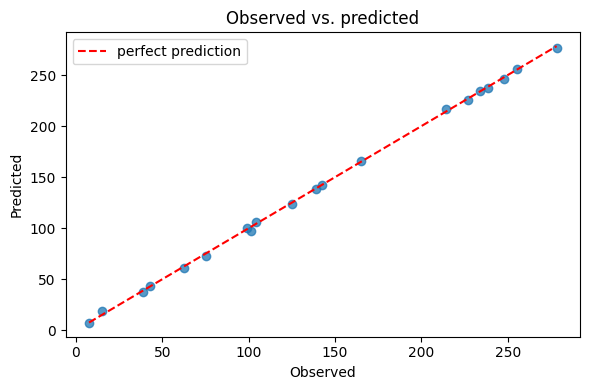

In [12]:
# Smoke test with deterministic synthetic data.
rng = np.random.default_rng(RANDOM_STATE)
features = pd.DataFrame({"x": np.arange(100, dtype=float)})
target = 3 * features["x"] + 7 + rng.normal(0, 2, size=len(features))

x_train, x_test, y_train, y_test = split_data(features, target)
model = train_model(x_train, y_train)
metrics = evaluate_model(model, x_test, y_test)

print(f"coefficient: {model.coef_[0]:.3f}")
print(f"intercept: {model.intercept_:.3f}")
print({name: round(value, 3) for name, value in metrics.items()})
plot_predictions(model, x_test, y_test)